## **Tarefa da aula sobre dummies e Multidimensionalidade**

---

# 1. Vamos usar um conjunto de dados fictício de uma loja que contém informações sobre clientes e suas compras. O conjunto de dados tem variáveis categóricas e textuais.

In [1]:
data = {
    'CustomerID': [1, 2, 3, 4],
    'Name': ['Alice Johnson', 'Bob Smith', 'Charlie Brown', 'David Wilson'],
    'City': ['New York', 'Los Angeles', 'New York', 'Chicago'],
    'PurchaseAmount': [200, 150, 300, 250],
    'Gender': ['Female', 'Male', 'Male', 'Male'],
    'Membership': ['Premium', 'Standard', 'Standard', 'Premium']
}

---

# Importando as Bibliotecas

In [2]:
import numpy as np
import pandas as pd

---

# Verificando as informações da base de dados

In [3]:
df = pd.DataFrame(data)

In [4]:
df

,CustomerID,Name,City,PurchaseAmount,Gender,Membership
0,1,Alice Johnson,New York,200,Female,Premium
1,2,Bob Smith,Los Angeles,150,Male,Standard
2,3,Charlie Brown,New York,300,Male,Standard
3,4,David Wilson,Chicago,250,Male,Premium


In [5]:
df.shape

(4, 6)

In [6]:
df.dtypes

,0
CustomerID,int64
Name,object
City,object
PurchaseAmount,int64
Gender,object
Membership,object


---

# 2. Transformar variáveis categóricas em variáveis dummy para uso em modelos de machine learning.

Variáveis que vou transformar em dummies: 'City', 'Gender' e 'Membership'

In [7]:
df_dummies_bool = pd.get_dummies(df, columns=['City', 'Gender', 'Membership'])

print("\nDataFrame com Variáveis Dummy:")
df_dummies_bool


DataFrame com Variáveis Dummy:


,CustomerID,Name,PurchaseAmount,City_Chicago,City_Los Angeles,City_New York,Gender_Female,Gender_Male,Membership_Premium,Membership_Standard
0,1,Alice Johnson,200,False,False,True,True,False,True,False
1,2,Bob Smith,150,False,True,False,False,True,False,True
2,3,Charlie Brown,300,False,False,True,False,True,False,True
3,4,David Wilson,250,True,False,False,False,True,True,False


In [8]:
df_dummies_bool.dtypes
# todas as colunas dummies são valores booleanos!

,0
CustomerID,int64
Name,object
PurchaseAmount,int64
City_Chicago,bool
City_Los Angeles,bool
City_New York,bool
Gender_Female,bool
Gender_Male,bool
Membership_Premium,bool
Membership_Standard,bool


In [9]:
df_dummies = pd.get_dummies(df, columns=['City', 'Gender', 'Membership'], dtype=int)
# dessa forma, é possível criar as colunas dummy diretamente como valores inteiros (0 ou 1).

print("\nDataFrame com Variáveis Dummy:")
df_dummies


DataFrame com Variáveis Dummy:


,CustomerID,Name,PurchaseAmount,City_Chicago,City_Los Angeles,City_New York,Gender_Female,Gender_Male,Membership_Premium,Membership_Standard
0,1,Alice Johnson,200,0,0,1,1,0,1,0
1,2,Bob Smith,150,0,1,0,0,1,0,1
2,3,Charlie Brown,300,0,0,1,0,1,0,1
3,4,David Wilson,250,1,0,0,0,1,1,0


In [10]:
df_dummies.dtypes
# todos as colunas dummies são valores inteiros agora!

,0
CustomerID,int64
Name,object
PurchaseAmount,int64
City_Chicago,int64
City_Los Angeles,int64
City_New York,int64
Gender_Female,int64
Gender_Male,int64
Membership_Premium,int64
Membership_Standard,int64


---

# 3. Limpar e preparar dados textuais para análise.

Vou trabalhar apenas com o df_dummies (que recebeu os valores como int)

In [11]:
df_dummies

,CustomerID,Name,PurchaseAmount,City_Chicago,City_Los Angeles,City_New York,Gender_Female,Gender_Male,Membership_Premium,Membership_Standard
0,1,Alice Johnson,200,0,0,1,1,0,1,0
1,2,Bob Smith,150,0,1,0,0,1,0,1
2,3,Charlie Brown,300,0,0,1,0,1,0,1
3,4,David Wilson,250,1,0,0,0,1,1,0


In [12]:
df_dummies['Name'] = df['Name'].str.lower()

df_dummies
# exibindo o DataFrame após alterações dos dados textuais

,CustomerID,Name,PurchaseAmount,City_Chicago,City_Los Angeles,City_New York,Gender_Female,Gender_Male,Membership_Premium,Membership_Standard
0,1,alice johnson,200,0,0,1,1,0,1,0
1,2,bob smith,150,0,1,0,0,1,0,1
2,3,charlie brown,300,0,0,1,0,1,0,1
3,4,david wilson,250,1,0,0,0,1,1,0


---

# 4 Realizar uma limpeza adicional nos dados.

Como o objetivo aqui é preparar dados para modelos de machine learning, acredito que devo remover as colunas 'CustomerID' e 'Name', pois são identificadores únicos e não possuem nenhum padrão para que possam ser variáveis preditivas.

In [13]:
# removendo as colunas de identificadores que são não preditivas
df_clean = df_dummies.drop(columns=['CustomerID', 'Name'])

df_clean

,PurchaseAmount,City_Chicago,City_Los Angeles,City_New York,Gender_Female,Gender_Male,Membership_Premium,Membership_Standard
0,200,0,0,1,1,0,1,0
1,150,0,1,0,0,1,0,1
2,300,0,0,1,0,1,0,1
3,250,1,0,0,0,1,1,0


Agora o nosso DataFrame possui apenas dados numéricos!

---

# 5. Crie um novo DataFrame com variáveis categóricas adicionais.

Adicione uma coluna 'Country' e crie variáveis dummy para ela.

In [14]:
# adicionando a coluna 'Country' ao df original

df['Country'] = ['USA', 'Canada', 'USA', 'Canada']

df

,CustomerID,Name,City,PurchaseAmount,Gender,Membership,Country
0,1,Alice Johnson,New York,200,Female,Premium,USA
1,2,Bob Smith,Los Angeles,150,Male,Standard,Canada
2,3,Charlie Brown,New York,300,Male,Standard,USA
3,4,David Wilson,Chicago,250,Male,Premium,Canada


In [15]:
# criando os dummies usando dtype como int

new_df_dummies = pd.get_dummies(df, columns=['Country'], dtype=int)

new_df_dummies

,CustomerID,Name,City,PurchaseAmount,Gender,Membership,Country_Canada,Country_USA
0,1,Alice Johnson,New York,200,Female,Premium,0,1
1,2,Bob Smith,Los Angeles,150,Male,Standard,1,0
2,3,Charlie Brown,New York,300,Male,Standard,0,1
3,4,David Wilson,Chicago,250,Male,Premium,1,0


---

# 6. Separe a coluna 'City' em 'CityName' e 'State' (simule que há um estado separado por um hífen).

Manipule strings e Realize a limpeza adicional:

In [16]:
# criando uma coluna simulada
df['City_State_Simulated'] = ['New York-NY', 'Los Angeles-CA', 'New York-NY', 'Chicago-IL']

# criando duas colunas separadas para cada uma receber um dos valores que serão separados
df[['CityName', 'State']] = df['City_State_Simulated'].str.split('-', expand=True) # o argumento 'expand=True' força o texto separado a entrar em duas colunas diferentes

df

,CustomerID,Name,City,PurchaseAmount,Gender,Membership,Country,City_State_Simulated,CityName,State
0,1,Alice Johnson,New York,200,Female,Premium,USA,New York-NY,New York,NY
1,2,Bob Smith,Los Angeles,150,Male,Standard,Canada,Los Angeles-CA,Los Angeles,CA
2,3,Charlie Brown,New York,300,Male,Standard,USA,New York-NY,New York,NY
3,4,David Wilson,Chicago,250,Male,Premium,Canada,Chicago-IL,Chicago,IL


Realizando a limpeza adicional nesse novo DataFrame que fiz

In [17]:
# removendo colunas que agora são inúteis
df.drop(columns=['City', 'Country', 'City_State_Simulated'], inplace=True)

df

,CustomerID,Name,PurchaseAmount,Gender,Membership,CityName,State
0,1,Alice Johnson,200,Female,Premium,New York,NY
1,2,Bob Smith,150,Male,Standard,Los Angeles,CA
2,3,Charlie Brown,300,Male,Standard,New York,NY
3,4,David Wilson,250,Male,Premium,Chicago,IL


Repetir o processo que fiz: criar os dummies, limpar dados textuais e fazer uma limpeza final para ficarmos apenas com dados numéricos prontos para modelos de Machine Learning

In [18]:
df_city_state_dummies = pd.get_dummies(df, columns=['Gender', 'Membership', 'CityName', 'State'], dtype=int)

df_city_state_dummies

,CustomerID,Name,PurchaseAmount,Gender_Female,Gender_Male,Membership_Premium,Membership_Standard,CityName_Chicago,CityName_Los Angeles,CityName_New York,State_CA,State_IL,State_NY
0,1,Alice Johnson,200,1,0,1,0,0,0,1,0,0,1
1,2,Bob Smith,150,0,1,0,1,0,1,0,1,0,0
2,3,Charlie Brown,300,0,1,0,1,0,0,1,0,0,1
3,4,David Wilson,250,0,1,1,0,1,0,0,0,1,0


In [19]:
df_city_state_dummies.dtypes

,0
CustomerID,int64
Name,object
PurchaseAmount,int64
Gender_Female,int64
Gender_Male,int64
Membership_Premium,int64
Membership_Standard,int64
CityName_Chicago,int64
CityName_Los Angeles,int64
CityName_New York,int64


In [20]:
# removendo as colunas que são de valores identificadores

df_city_state_dummies.drop(columns=['CustomerID', 'Name'], inplace=True)

df_city_state_dummies

,PurchaseAmount,Gender_Female,Gender_Male,Membership_Premium,Membership_Standard,CityName_Chicago,CityName_Los Angeles,CityName_New York,State_CA,State_IL,State_NY
0,200,1,0,1,0,0,0,1,0,0,1
1,150,0,1,0,1,0,1,0,1,0,0
2,300,0,1,0,1,0,0,1,0,0,1
3,250,0,1,1,0,1,0,0,0,1,0


In [21]:
df_city_state_dummies.dtypes

,0
PurchaseAmount,int64
Gender_Female,int64
Gender_Male,int64
Membership_Premium,int64
Membership_Standard,int64
CityName_Chicago,int64
CityName_Los Angeles,int64
CityName_New York,int64
State_CA,int64
State_IL,int64


Agora temos apenas valores numéricos!

In [22]:
# verificando valores duplicados ou nulos

city_state_duplicates = df_city_state_dummies.duplicated().sum()
print('Número de entradas duplicadas no df_city_state_dummies: ', city_state_duplicates)

print('\nValores nulos no df_city_state_dummies: ')
df_city_state_dummies.isnull().sum()


Número de entradas duplicadas no df_city_state_dummies:  0

Valores nulos no df_city_state_dummies: 


,0
PurchaseAmount,0
Gender_Female,0
Gender_Male,0
Membership_Premium,0
Membership_Standard,0
CityName_Chicago,0
CityName_Los Angeles,0
CityName_New York,0
State_CA,0
State_IL,0


---

## Trabalhando com dados no formato json

In [23]:
import requests
import pandas as pd

In [24]:
pip install requests pandas

In [25]:
pip install requests

---

Obtendo os dados e salvando em um DataFrame

In [26]:
# URL da API JSONPlaceholder
users_url = 'https://jsonplaceholder.typicode.com/users'
posts_url = 'https://jsonplaceholder.typicode.com/posts'

# Função para obter dados de uma URL
def fetch_data(url):
    response = requests.get(url)
    response.raise_for_status()  # Verifica se ocorreu um erro
    return response.json()

# Obter dados dos usuários
users_data = fetch_data(users_url)
print("Dados dos usuários:")
print(users_data)

# Obter dados dos posts
posts_data = fetch_data(posts_url)
print("\nDados dos posts:")
print(posts_data)

# Converter dados para DataFrame pandas
users_df = pd.DataFrame(users_data)
posts_df = pd.DataFrame(posts_data)

# Exibir os primeiros registros
print("\nDataFrame dos usuários:")
print(users_df.head())

print("\nDataFrame dos posts:")
print(posts_df.head())

Dados dos usuários:
[{'id': 1, 'name': 'Leanne Graham', 'username': 'Bret', 'email': 'Sincere@april.biz', 'address': {'street': 'Kulas Light', 'suite': 'Apt. 556', 'city': 'Gwenborough', 'zipcode': '92998-3874', 'geo': {'lat': '-37.3159', 'lng': '81.1496'}}, 'phone': '1-770-736-8031 x56442', 'website': 'hildegard.org', 'company': {'name': 'Romaguera-Crona', 'catchPhrase': 'Multi-layered client-server neural-net', 'bs': 'harness real-time e-markets'}}, {'id': 2, 'name': 'Ervin Howell', 'username': 'Antonette', 'email': 'Shanna@melissa.tv', 'address': {'street': 'Victor Plains', 'suite': 'Suite 879', 'city': 'Wisokyburgh', 'zipcode': '90566-7771', 'geo': {'lat': '-43.9509', 'lng': '-34.4618'}}, 'phone': '010-692-6593 x09125', 'website': 'anastasia.net', 'company': {'name': 'Deckow-Crist', 'catchPhrase': 'Proactive didactic contingency', 'bs': 'synergize scalable supply-chains'}}, {'id': 3, 'name': 'Clementine Bauch', 'username': 'Samantha', 'email': 'Nathan@yesenia.net', 'address': {'str

Exibindo novamente os DataFrames sem a função print()

In [27]:
users_df.head()

,id,name,username,email,address,phone,website,company
0,1,Leanne Graham,Bret,Sincere@april.biz,"{'street': 'Kulas Light', 'suite': 'Apt. 556',...",1-770-736-8031 x56442,hildegard.org,"{'name': 'Romaguera-Crona', 'catchPhrase': 'Mu..."
1,2,Ervin Howell,Antonette,Shanna@melissa.tv,"{'street': 'Victor Plains', 'suite': 'Suite 87...",010-692-6593 x09125,anastasia.net,"{'name': 'Deckow-Crist', 'catchPhrase': 'Proac..."
2,3,Clementine Bauch,Samantha,Nathan@yesenia.net,"{'street': 'Douglas Extension', 'suite': 'Suit...",1-463-123-4447,ramiro.info,"{'name': 'Romaguera-Jacobson', 'catchPhrase': ..."
3,4,Patricia Lebsack,Karianne,Julianne.OConner@kory.org,"{'street': 'Hoeger Mall', 'suite': 'Apt. 692',...",493-170-9623 x156,kale.biz,"{'name': 'Robel-Corkery', 'catchPhrase': 'Mult..."
4,5,Chelsey Dietrich,Kamren,Lucio_Hettinger@annie.ca,"{'street': 'Skiles Walks', 'suite': 'Suite 351...",(254)954-1289,demarco.info,"{'name': 'Keebler LLC', 'catchPhrase': 'User-c..."


In [28]:
posts_df.head()

,userId,id,title,body
0,1,1,sunt aut facere repellat provident occaecati e...,quia et suscipit\nsuscipit recusandae consequu...
1,1,2,qui est esse,est rerum tempore vitae\nsequi sint nihil repr...
2,1,3,ea molestias quasi exercitationem repellat qui...,et iusto sed quo iure\nvoluptatem occaecati om...
3,1,4,eum et est occaecati,ullam et saepe reiciendis voluptatem adipisci\...
4,1,5,nesciunt quas odio,repudiandae veniam quaerat sunt sed\nalias aut...


---

# Manipule os dados presentes: formatando o DataFrame users_df

Temos colunas que são dicionários dentro do DataFrame users_df

In [29]:
# expandir as colunas 'address' e 'company' e transformando em DataFrames isolados
address_expanded = users_df['address'].apply(pd.Series)
company_expanded = users_df['company'].apply(pd.Series)

# exibir os DataFrames resultantes
print("DataFrame address_expanded:")
print(address_expanded.head())

print("\nDataFrame company_expanded:")
print(company_expanded.head())

DataFrame address_expanded:
              street      suite           city     zipcode  \
0        Kulas Light   Apt. 556    Gwenborough  92998-3874   
1      Victor Plains  Suite 879    Wisokyburgh  90566-7771   
2  Douglas Extension  Suite 847  McKenziehaven  59590-4157   
3        Hoeger Mall   Apt. 692    South Elvis  53919-4257   
4       Skiles Walks  Suite 351     Roscoeview       33263   

                                      geo  
0   {'lat': '-37.3159', 'lng': '81.1496'}  
1  {'lat': '-43.9509', 'lng': '-34.4618'}  
2  {'lat': '-68.6102', 'lng': '-47.0653'}  
3  {'lat': '29.4572', 'lng': '-164.2990'}  
4   {'lat': '-31.8129', 'lng': '62.5342'}  

DataFrame company_expanded:
                 name                               catchPhrase  \
0     Romaguera-Crona    Multi-layered client-server neural-net   
1        Deckow-Crist            Proactive didactic contingency   
2  Romaguera-Jacobson         Face to face bifurcated interface   
3       Robel-Corkery  Multi-tiered ze

In [30]:
# ainda tínhamos a coluna 'geo' do 'address_expanded' que continha um dicionário
# por isso vou fazer o .apply(pd.Series) nessa coluna para formatar

geo_expanded = address_expanded['geo'].apply(pd.Series)
address_expanded.drop(columns=['geo'], inplace=True)

# exibir os DataFrames resultantes
print("DataFrame geo_expanded:")
print(geo_expanded.head())

print("\nDataFrame address_expanded com a coluna geo removida:")
print(address_expanded.head())

DataFrame geo_expanded:
        lat        lng
0  -37.3159    81.1496
1  -43.9509   -34.4618
2  -68.6102   -47.0653
3   29.4572  -164.2990
4  -31.8129    62.5342

DataFrame address_expanded com a coluna geo removida:
              street      suite           city     zipcode
0        Kulas Light   Apt. 556    Gwenborough  92998-3874
1      Victor Plains  Suite 879    Wisokyburgh  90566-7771
2  Douglas Extension  Suite 847  McKenziehaven  59590-4157
3        Hoeger Mall   Apt. 692    South Elvis  53919-4257
4       Skiles Walks  Suite 351     Roscoeview       33263


Agora devemos concatenar o DataFrame users_df com os DataFrames 'address_expanded', 'geo_expanded' e 'company_expanded'

In [31]:
# adicionar prefixos para evitar conflitos entre os nomes das colunas (tanto a companhia quanto o usuário podem ter um nome)
address_expanded = address_expanded.add_prefix('address_')
geo_expanded = geo_expanded.add_prefix('address_')
company_expanded = company_expanded.add_prefix('company_')

# concatenar as novas colunas de volta ao DataFrame original e remover as colunas antigas de dicionário
users_df = pd.concat([users_df.drop(columns=['address', 'company']), address_expanded, geo_expanded, company_expanded], axis='columns')

# exibir resultado
users_df.head()

,id,name,username,email,phone,website,address_street,address_suite,address_city,address_zipcode,address_lat,address_lng,company_name,company_catchPhrase,company_bs
0,1,Leanne Graham,Bret,Sincere@april.biz,1-770-736-8031 x56442,hildegard.org,Kulas Light,Apt. 556,Gwenborough,92998-3874,-37.3159,81.1496,Romaguera-Crona,Multi-layered client-server neural-net,harness real-time e-markets
1,2,Ervin Howell,Antonette,Shanna@melissa.tv,010-692-6593 x09125,anastasia.net,Victor Plains,Suite 879,Wisokyburgh,90566-7771,-43.9509,-34.4618,Deckow-Crist,Proactive didactic contingency,synergize scalable supply-chains
2,3,Clementine Bauch,Samantha,Nathan@yesenia.net,1-463-123-4447,ramiro.info,Douglas Extension,Suite 847,McKenziehaven,59590-4157,-68.6102,-47.0653,Romaguera-Jacobson,Face to face bifurcated interface,e-enable strategic applications
3,4,Patricia Lebsack,Karianne,Julianne.OConner@kory.org,493-170-9623 x156,kale.biz,Hoeger Mall,Apt. 692,South Elvis,53919-4257,29.4572,-164.2990,Robel-Corkery,Multi-tiered zero tolerance productivity,transition cutting-edge web services
4,5,Chelsey Dietrich,Kamren,Lucio_Hettinger@annie.ca,(254)954-1289,demarco.info,Skiles Walks,Suite 351,Roscoeview,33263,-31.8129,62.5342,Keebler LLC,User-centric fault-tolerant solution,revolutionize end-to-end systems


Agora o DataFrame users_df foi formatado e os dicionários foram removidos!

---

# 7. Remova quaisquer entradas duplicadas e verifique por valores ausentes.

In [32]:
users_df.shape

(10, 15)

In [33]:
posts_df.shape

(100, 4)

In [34]:
# verificando entradas duplicadas

users_duplicated = users_df.duplicated().sum()
print('Número de entradas duplicadas no users_df: ', users_duplicated)


Número de entradas duplicadas no users_df:  0


In [35]:
# verificando entradas duplicadas

posts_duplicated = posts_df.duplicated().sum()
print('Número de entradas duplicadas no posts_df: ', posts_duplicated)

Número de entradas duplicadas no posts_df:  0


In [36]:
users_df.isnull().sum()
# nenhum valor nulo no DataFrame dos usuários!

,0
id,0
name,0
username,0
email,0
phone,0
website,0
address_street,0
address_suite,0
address_city,0
address_zipcode,0


In [37]:
posts_df.isnull().sum()
# nenhum valor nulo no DataFrame dos posts!

,0
userId,0
id,0
title,0
body,0


---

# Realize algumas visualizações simples

In [38]:
import matplotlib.pyplot as plt

# Obter dados dos comentários
comments_url = 'https://jsonplaceholder.typicode.com/comments'
comments_data = fetch_data(comments_url)
comments_df = pd.DataFrame(comments_data)

# Exibir os primeiros registros
print("\nDataFrame dos Comentários:")
comments_df.head()


DataFrame dos Comentários:


,postId,id,name,email,body
0,1,1,id labore ex et quam laborum,Eliseo@gardner.biz,laudantium enim quasi est quidem magnam volupt...
1,1,2,quo vero reiciendis velit similique earum,Jayne_Kuhic@sydney.com,est natus enim nihil est dolore omnis voluptat...
2,1,3,odio adipisci rerum aut animi,Nikita@garfield.biz,quia molestiae reprehenderit quasi aspernatur\...
3,1,4,alias odio sit,Lew@alysha.tv,non et atque\noccaecati deserunt quas accusant...
4,1,5,vero eaque aliquid doloribus et culpa,Hayden@althea.biz,harum non quasi et ratione\ntempore iure ex vo...


In [39]:
# imprindo todos os DataFrames só p/ referência
print("DataFrame dos usuários:")
print(users_df.head())

print("\nDataFrame dos posts:")
print(posts_df.head())

print("\nDataFrame dos comentários:")
print(comments_df.head())

DataFrame dos usuários:
   id              name   username                      email  \
0   1     Leanne Graham       Bret          Sincere@april.biz   
1   2      Ervin Howell  Antonette          Shanna@melissa.tv   
2   3  Clementine Bauch   Samantha         Nathan@yesenia.net   
3   4  Patricia Lebsack   Karianne  Julianne.OConner@kory.org   
4   5  Chelsey Dietrich     Kamren   Lucio_Hettinger@annie.ca   

                   phone        website     address_street address_suite  \
0  1-770-736-8031 x56442  hildegard.org        Kulas Light      Apt. 556   
1    010-692-6593 x09125  anastasia.net      Victor Plains     Suite 879   
2         1-463-123-4447    ramiro.info  Douglas Extension     Suite 847   
3      493-170-9623 x156       kale.biz        Hoeger Mall      Apt. 692   
4          (254)954-1289   demarco.info       Skiles Walks     Suite 351   

    address_city address_zipcode address_lat address_lng        company_name  \
0    Gwenborough      92998-3874    -37.3159    

In [40]:
comments_df.shape

(500, 5)

Gráfico do Número de Comentários por Usuário

In [41]:
# juntar os dataframes dos comentários e posts
# estou pegando apenas 'id' e 'userId' dos posts para conectar o comentário ao usuário

comments_with_users = pd.merge(
    comments_df,
    posts_df[['id', 'userId']],
    left_on='postId',
    right_on='id'
)

comments_with_users.head()

,postId,id_x,name,email,body,id_y,userId
0,1,1,id labore ex et quam laborum,Eliseo@gardner.biz,laudantium enim quasi est quidem magnam volupt...,1,1
1,1,2,quo vero reiciendis velit similique earum,Jayne_Kuhic@sydney.com,est natus enim nihil est dolore omnis voluptat...,1,1
2,1,3,odio adipisci rerum aut animi,Nikita@garfield.biz,quia molestiae reprehenderit quasi aspernatur\...,1,1
3,1,4,alias odio sit,Lew@alysha.tv,non et atque\noccaecati deserunt quas accusant...,1,1
4,1,5,vero eaque aliquid doloribus et culpa,Hayden@althea.biz,harum non quasi et ratione\ntempore iure ex vo...,1,1


In [42]:
# contar o número de comentários para cada userId e ordenar por userId
comments_per_user = comments_with_users['userId'].value_counts().sort_index()

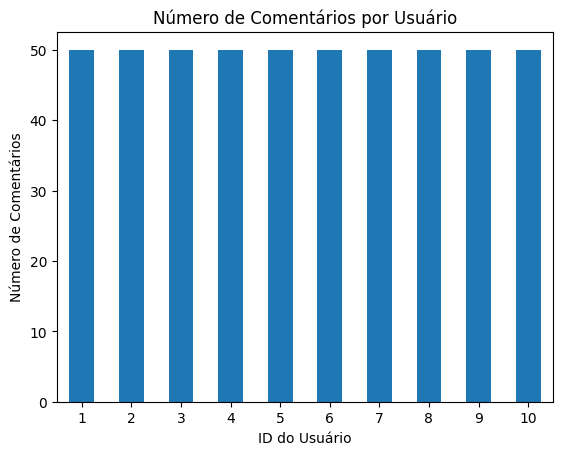

In [43]:
# criar o gráfico de barras
comments_per_user.plot(kind='bar', title='Número de Comentários por Usuário')

# adicionar labels ao gráfico
plt.xlabel('ID do Usuário')
plt.ylabel('Número de Comentários')
plt.xticks(rotation=0)

# Display the chart
plt.show()

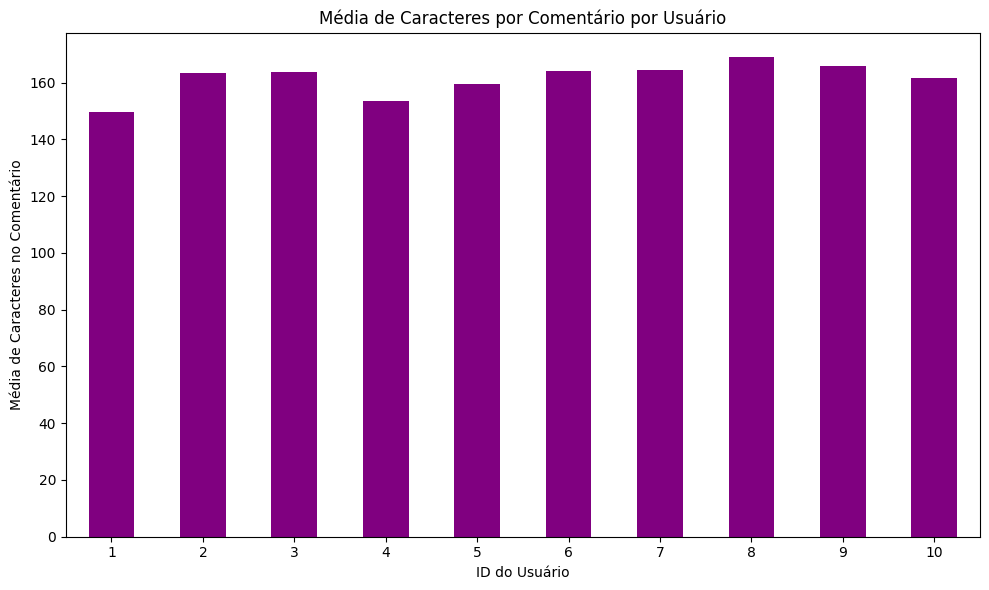

,body_length
userId,
1,149.74
2,163.30
3,163.78
4,153.56
5,159.38
6,164.20
7,164.52
8,169.10
9,166.04


In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

# fazendo um gráfico com a média de caracteres (comprimento) dos comentários de cada usuário

# calcular o comprimento (len) de cada comentário
comments_with_users['body_length'] = comments_with_users['body'].apply(len)

users_grp = comments_with_users.groupby('userId')

# agregar a média de 'body_length'
mean_body_length_per_user = users_grp['body_length'].agg('mean')

# visualização
plt.figure(figsize=(10, 6))
mean_body_length_per_user.plot(kind='bar', title='Média de Caracteres por Comentário por Usuário', color='purple')
plt.xlabel('ID do Usuário')
plt.ylabel('Média de Caracteres no Comentário')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

mean_body_length_per_user

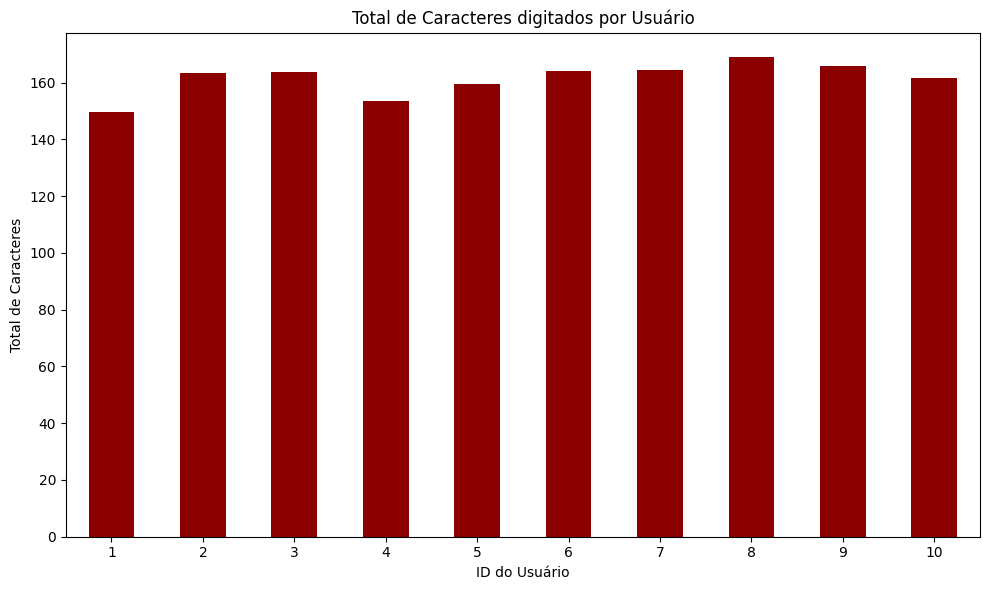

,body_length
userId,
1,149.74
2,163.30
3,163.78
4,153.56
5,159.38
6,164.20
7,164.52
8,169.10
9,166.04


In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

# fazendo um gráfico com o total de caracteres (soma) digitados por cada usuário

# calcular o comprimento (len) de cada comentário
comments_with_users['body_length'] = comments_with_users['body'].apply(len)

users_grp = comments_with_users.groupby('userId')

# agregar a média de 'body_length'
total_characters_per_user = users_grp['body_length'].agg('sum')

# visualização
plt.figure(figsize=(10, 6))
mean_body_length_per_user.plot(kind='bar', title='Total de Caracteres digitados por Usuário', color='darkred')
plt.xlabel('ID do Usuário')
plt.ylabel('Total de Caracteres')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

mean_body_length_per_user